In [1]:
from dataclasses import dataclass

import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
from fontTools.misc.bezierTools import epsilon

from core.entities.constants import Paths as p

In [2]:
img_path = p.IMAGE_ASSETS / "tesla.png"
img = cv.imread(img_path, cv.IMREAD_GRAYSCALE)

In [3]:
img = img[1090:1170, 1430:1560]

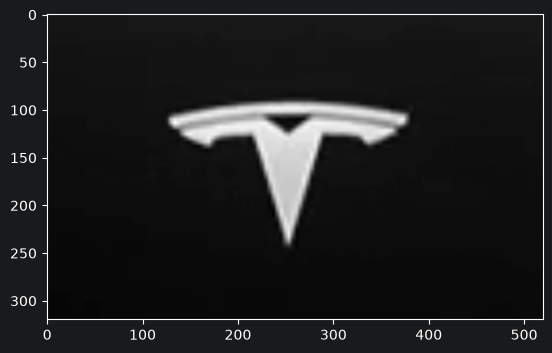

In [4]:
scale = 4

h_scaled, w_scaled = map(lambda x: int(x * scale), img.shape[:2])
img = cv.resize(img, (w_scaled, h_scaled), interpolation=cv.INTER_LINEAR)
plt.figure()
plt.imshow(img, cmap="gray")

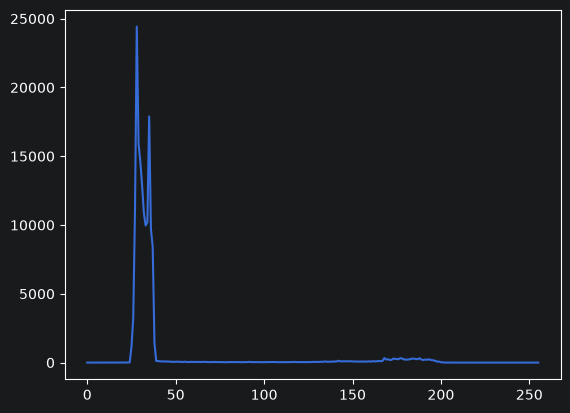

In [5]:
hist = cv.calcHist([img], [0], None, [256], [0, 256])
plt.figure()
plt.plot(hist)

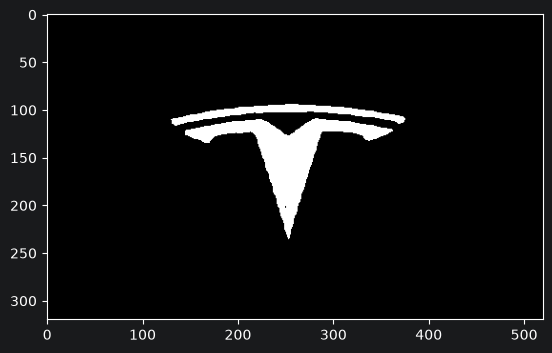

In [6]:
thresh = cv.threshold(img, 160, 255, cv.THRESH_BINARY)[1]
plt.figure()
plt.imshow(thresh, cmap="gray")

In [9]:
@dataclass(frozen=True)
class TrackbarNames:
    DILATE_K: str = "dilate_k"
    MODE: str = "mode"
    METHOD: str = "method"
    IDX: str = "idx"
    THICKNESS: str = "thickness"

MODES = [cv.RETR_TREE, cv.RETR_EXTERNAL]
METHODS = [cv.CHAIN_APPROX_SIMPLE, cv.CHAIN_APPROX_NONE]

In [10]:
def contours_callback(value):
    pass

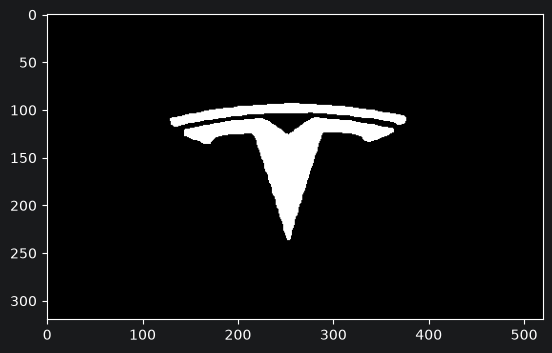

In [11]:
window_name = "contours"

cv.namedWindow(window_name)
cfg = TrackbarNames()
cv.createTrackbar(cfg.DILATE_K, window_name, 0, 11, contours_callback)
cv.createTrackbar(cfg.MODE, window_name, 0, 1, contours_callback)
cv.createTrackbar(cfg.METHOD, window_name, 0, 1, contours_callback)
cv.createTrackbar(cfg.IDX, window_name, -1, 100, contours_callback)
cv.setTrackbarMin(cfg.IDX, window_name, -1)
cv.setTrackbarPos(cfg.IDX, window_name, -1)
cv.createTrackbar(cfg.THICKNESS, window_name, -1, 3, contours_callback)
cv.setTrackbarMin(cfg.THICKNESS, window_name, -1)
cv.setTrackbarPos(cfg.THICKNESS, window_name, -1)

contours = []

while True:
    if cv.waitKey(1) == ord("q"):
        break

    # DILATATION
    dilate_kernel = cv.getTrackbarPos(cfg.DILATE_K, window_name)
    if dilate_kernel == 0:
        dilated = thresh.copy()
    else:
        if dilate_kernel % 2 == 0:
            dilate_kernel += 1
            cv.setTrackbarPos(cfg.DILATE_K, window_name, dilate_kernel)

        kernel = np.ones((dilate_kernel, dilate_kernel), np.uint8)
        dilated = cv.dilate(thresh, kernel)

    # FIND CONTOURS
    mode_idx = cv.getTrackbarPos(cfg.MODE, window_name)
    method_idx = cv.getTrackbarPos(cfg.METHOD, window_name)
    mode = MODES[mode_idx]
    method = METHODS[method_idx]
    contours, _ = cv.findContours(dilated, mode, method)

    # DRAW CONTOURS
    contours_img = np.zeros_like(img)
    max_cnt_idx = len(contours) - 1
    cnt_idx = cv.getTrackbarPos(cfg.IDX, window_name)

    if cnt_idx > max_cnt_idx:
        cnt_idx = max_cnt_idx
        cv.setTrackbarPos(cfg.IDX, window_name, cnt_idx)

    thickness = cv.getTrackbarPos(cfg.THICKNESS, window_name)

    if thickness == 0:
        thickness = 1
        cv.setTrackbarPos(cfg.THICKNESS, window_name, thickness)

    cv.drawContours(contours_img, contours, cnt_idx, 255, thickness=thickness)

    cv.imshow(window_name, contours_img)
    cv.imshow("dilated", dilated)

cv.destroyAllWindows()

plt.figure()
plt.imshow(contours_img, cmap="gray")

### MOMETTS and center of mass

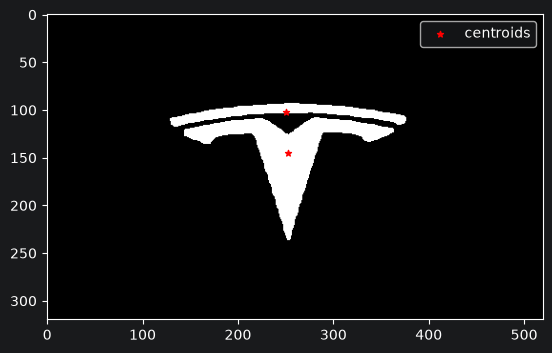

In [12]:
cx_list = []
cy_list = []

for cnt in contours:
    M = cv.moments(cnt)

    if M["m00"] != 0:
        cx = int(M["m10"] / M["m00"])
        cy = int(M["m01"] / M["m00"])
        cx_list.append(cx)
        cy_list.append(cy)

plt.figure()
plt.imshow(contours_img, cmap="gray")
plt.scatter(cx_list, cy_list, color="red", marker="*", s=20, label="centroids")
plt.legend()

### contour approximation

In [13]:
def approx_callback(value):
    pass

<Figure size 640x480 with 0 Axes>

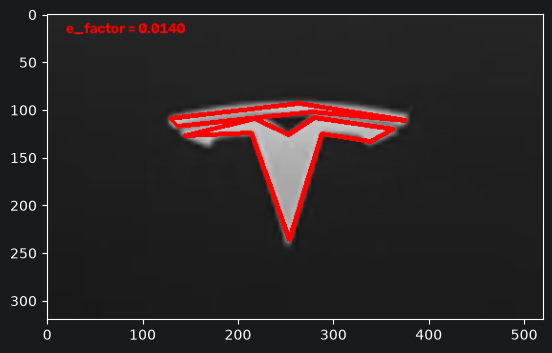

In [22]:
cv.window_name = "approximation"
cv.namedWindow(window_name)

cv.createTrackbar("e_factor", window_name, 100, 100, approx_callback)
cv.setTrackbarMin(window_name, window_name, 1)

plt.figure()

while True:
    if cv.waitKey(1) == ord("q"):
        break

    e_factor = cv.getTrackbarPos("e_factor", window_name) / 500


    approx_list = []

    for cnt in contours:
        perimeter = cv.arcLength(cnt, True)
        epsilon = e_factor * perimeter

        approx = cv.approxPolyDP(cnt, epsilon, True)
        approx_list.append(approx)
        # approx = np.array(approx)
        # approx = np.concatenate((approx, approx[:1]), axis=0)

    approx_img = cv.merge([img] * 3)
    cv.polylines(approx_img, approx_list, isClosed=True, color=[0, 0, 255], thickness=3)

    text = f"e_factor = {e_factor:.4f}"
    cv.putText(approx_img, text, (20, 20), fontFace=cv.FONT_HERSHEY_SIMPLEX, fontScale=0.5, color=[0, 0, 255], thickness=2)
    cv.imshow(window_name, approx_img)
        # plt.imshow(img, cmap="gray")
        #
        # plt.plot(approx[:, 0, 0], approx[:, 0, 1], color="green")

cv.destroyAllWindows()

approx_img =cv.cvtColor(approx_img, cv.COLOR_BGR2RGB)
plt.figure()
plt.imshow(approx_img)

### HULL

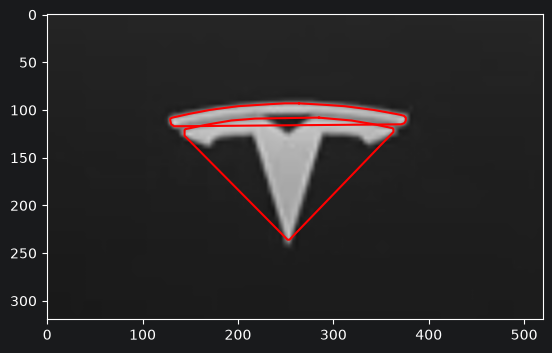

In [29]:
convex_img = cv.merge([img] * 3)
convex_img = cv.cvtColor(convex_img, cv.COLOR_BGR2RGB)

plt.figure()
plt.imshow(convex_img)

for cnt in contours:
    hull = cv.convexHull(cnt)
    hull = hull[:, 0, :]
    hull = np.concatenate([hull, hull[:1]], axis=0)

    plt.plot(hull[:, 0], hull[:, 1], "-", color="red")
    debug = 1

### BBOX

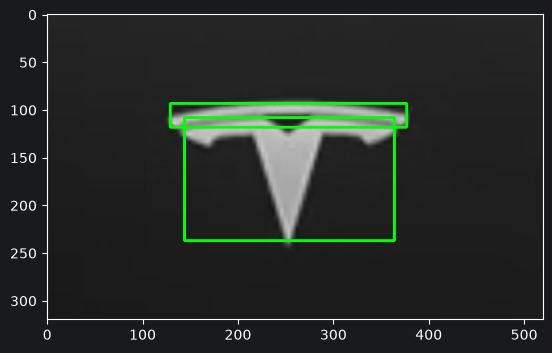

In [33]:
bbox_img = cv.merge([img] * 3)
bbox_img = cv.cvtColor(bbox_img, cv.COLOR_BGR2RGB)

for cnt in contours:
    x, y ,w, h = cv.boundingRect(cnt)
    cv.rectangle(bbox_img, (x, y), (x + w, y + h), (0, 255, 0), 2)

plt.figure()
plt.imshow(bbox_img)
